[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/09_clustering_scaffolds.ipynb)

# 09 · Clustering and Scaffold Analysis

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

Medicinal chemists think in **series**: a core scaffold decorated with different substituents.
Scaffold analysis and clustering organize a dataset into such series. They are used for
diverse-subset selection and SAR analysis, and (Notebook 11) for honest model validation.

**Learning objectives.** By the end of this notebook you will be able to:

- extract Bemis–Murcko scaffolds and generic frameworks
- summarize a dataset by its most frequent scaffolds
- cluster molecules with the Taylor–Butina algorithm
- relate clusters and scaffolds to activity

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
RDLogger.DisableLog("rdApp.*")
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import rdFingerprintGenerator
from rdkit.ML.Cluster import Butina

egfr = pd.read_csv(f"{DATA_DIR}/egfr_chembl37_ic50.csv")
egfr["mol"] = egfr["smiles"].apply(Chem.MolFromSmiles)
gefitinib = egfr.loc[egfr.compound_id == "CHEMBL939", "mol"].iloc[0]

## 1. Bemis–Murcko scaffolds

The Bemis–Murcko scaffold keeps ring systems and the linkers between them, and removes side chains.
The **generic** framework goes further: all atoms become carbon and all bonds single.

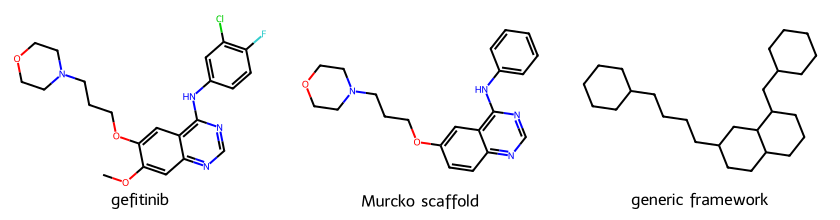

In [3]:
scaf = MurckoScaffold.GetScaffoldForMol(gefitinib)
generic = MurckoScaffold.MakeScaffoldGeneric(scaf)
Draw.MolsToGridImage([gefitinib, scaf, generic], legends=["gefitinib", "Murcko scaffold", "generic framework"],
                     subImgSize=(280, 220))

In [4]:
egfr["scaffold"] = egfr["mol"].apply(lambda m: Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(m)))
counts = egfr["scaffold"].value_counts()
print("compounds:", len(egfr), "| unique scaffolds:", len(counts),
      f"| singletons: {(counts == 1).sum()} ({(counts == 1).mean():.0%} of scaffolds)")
counts.head(10)

compounds: 6871 | unique scaffolds: 2659 | singletons: 1761 (66% of scaffolds)


scaffold
c1ccc(Nc2ncnc3ccccc23)cc1                               400
C1=C([C@@H](Nc2ccc3ncccc3c2)c2cccnc2)NNN1C1CC1          105
c1ccc(Nc2ccnc(Nc3ccccc3)n2)cc1                           98
c1ccc(CNc2ncnc3[nH]c(-c4ccccc4)cc23)cc1                  70
c1ccc(Nc2ccnc3ccccc23)cc1                                65
c1ccc(Nc2nccc(-c3c[nH]c4ccccc34)n2)cc1                   58
c1ccc(Oc2ccnc(Nc3ccc(N4CCNCC4)cc3)n2)cc1                 55
c1ccc(CNc2ncnc3sc(-c4ccccc4)cc23)cc1                     47
C1=C([C@@H](Nc2ccc3ncccc3c2)c2cccc3cnccc23)NNN1C1CC1     40
c1ccc(Nc2ncnc3ccc4c(c23)OCCO4)cc1                        39
Name: count, dtype: int64

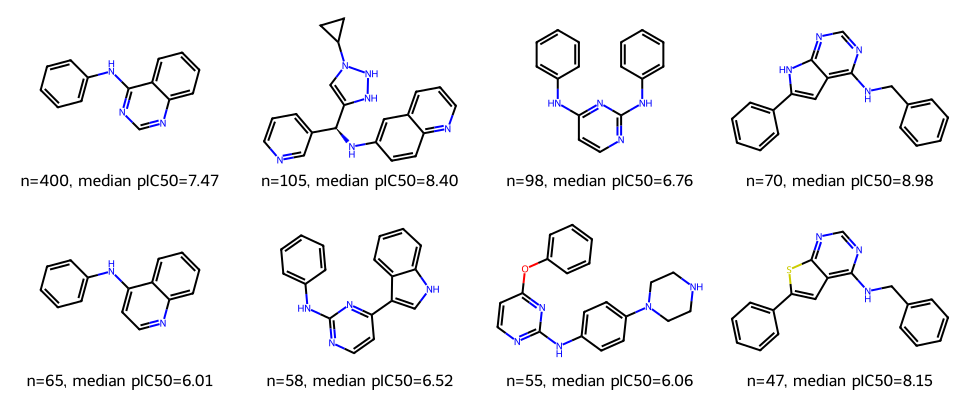

In [5]:
top = counts.head(8)
legends = [f"n={n}, median pIC50={egfr.loc[egfr.scaffold == s, 'p_activity'].median():.2f}" for s, n in top.items()]
Draw.MolsToGridImage([Chem.MolFromSmiles(s) if s else Chem.MolFromSmiles("C") for s in top.index],
                     molsPerRow=4, subImgSize=(240, 200), legends=legends)

An empty scaffold (`''`) would mean an acyclic molecule; it does not appear among the most frequent ones here.

## 2. How concentrated is the dataset?

A few scaffolds often account for a large share of compounds: the "big series" effect.

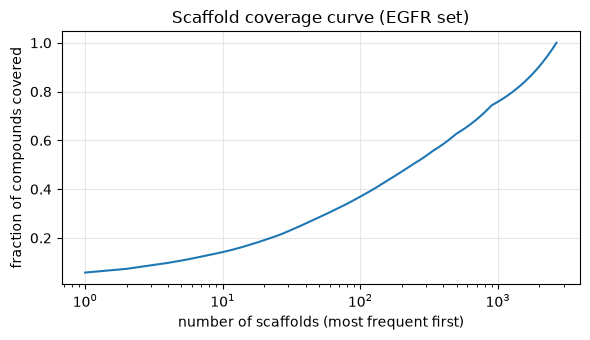

top 10 scaffolds cover 14.2% of compounds; top 100 cover 37.0%


In [6]:
cum = counts.cumsum() / counts.sum()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, len(cum) + 1), cum.values)
ax.set_xscale("log"); ax.set_xlabel("number of scaffolds (most frequent first)")
ax.set_ylabel("fraction of compounds covered"); ax.grid(alpha=0.3)
ax.set_title("Scaffold coverage curve (EGFR set)")
plt.tight_layout(); plt.show()
print(f"top 10 scaffolds cover {cum.iloc[9]:.1%} of compounds; top 100 cover {cum.iloc[99]:.1%}")

## 3. Taylor–Butina clustering

Butina clustering (Butina, *J. Chem. Inf. Comput. Sci.* 1999) uses fingerprint distances (1 − Tanimoto)
and a cut-off: each cluster centroid is the molecule with the most neighbours within the cut-off.
It needs the full pairwise distance matrix, so we cluster a random 1,500-compound subset.

In [7]:
sub = egfr.sample(1500, random_state=0).reset_index(drop=True)
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [mfpgen.GetFingerprint(m) for m in sub["mol"]]

def butina(fps, cutoff=0.6):
    dists = []
    for i in range(1, len(fps)):
        sims = DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])
        dists.extend(1 - s for s in sims)
    return Butina.ClusterData(dists, len(fps), cutoff, isDistData=True)

clusters = butina(fps, cutoff=0.6)          # distance 0.6 = Tanimoto 0.4
sizes = pd.Series([len(c) for c in clusters])
print(f"{len(clusters)} clusters | singletons: {(sizes == 1).sum()} | largest: {sizes.max()}")

284 clusters | singletons: 144 | largest: 209


In [8]:
sub["cluster"] = -1
for cid, members in enumerate(clusters):      # clusters are sorted largest first
    sub.loc[list(members), "cluster"] = cid

summary = (sub.groupby("cluster")["p_activity"].agg(size="size", median_pIC50="median", sd="std")
              .sort_values("size", ascending=False).head(8).round(2))
summary

,size,median_pIC50,sd
cluster,,,
0,209,8.22,0.54
1,174,7.78,1.02
2,76,7.54,1.04
4,71,6.76,1.02
8,56,7.43,0.80
3,51,7.07,1.50
6,25,7.44,0.94
32,24,5.26,0.48


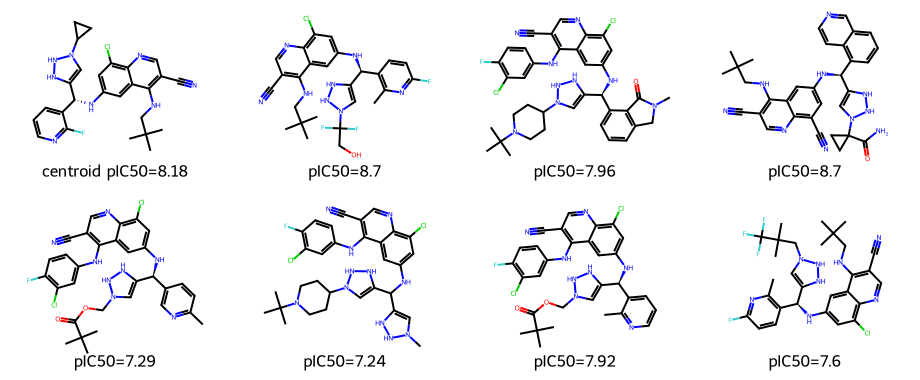

In [9]:
largest = clusters[0]
members = [largest[0]] + list(largest[1:8])      # the centroid comes first
Draw.MolsToGridImage([sub.loc[i, "mol"] for i in members], molsPerRow=4, subImgSize=(230, 190),
                     legends=[("centroid " if k == 0 else "") + f"pIC50={sub.loc[i, 'p_activity']}"
                              for k, i in enumerate(members)])

## 4. The cut-off controls everything

In [10]:
rows = []
for cutoff in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    cl = butina(fps, cutoff)
    s = np.array([len(c) for c in cl])
    rows.append({"distance cut-off": cutoff, "Tanimoto ≥": round(1 - cutoff, 1),
                 "clusters": len(cl), "singletons": int((s == 1).sum()), "largest": int(s.max())})
pd.DataFrame(rows)

,distance cut-off,Tanimoto ≥,clusters,singletons,largest
0,0.3,0.7,862,613,27
1,0.4,0.6,587,353,75
2,0.5,0.5,396,221,159
3,0.6,0.4,284,144,209
4,0.7,0.3,177,80,396
5,0.8,0.2,70,25,900


## 5. Picking a diverse subset

One centroid per cluster gives a diverse, representative subset, which is useful for choosing compounds to buy or test.

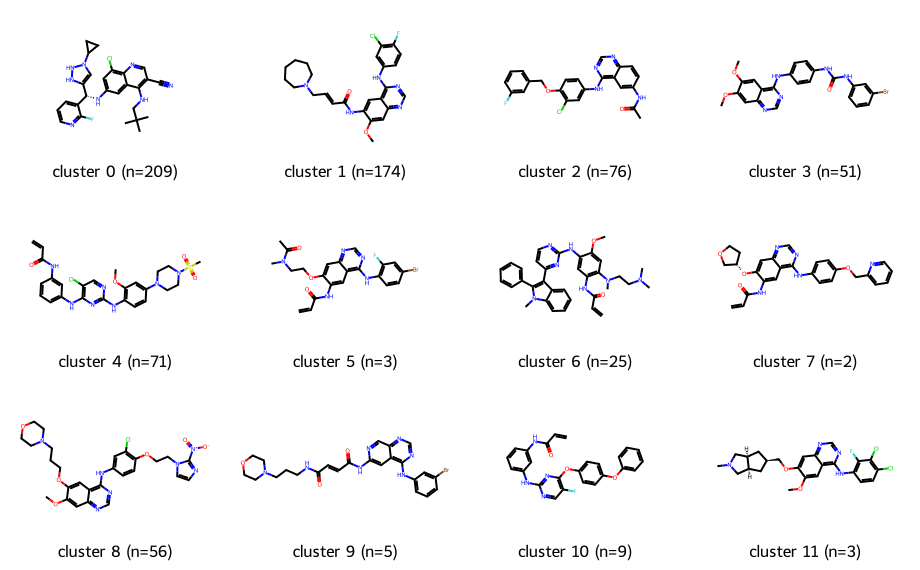

In [11]:
centroids = [c[0] for c in clusters if len(c) >= 5][:12]
Draw.MolsToGridImage([sub.loc[i, "mol"] for i in centroids], molsPerRow=4, subImgSize=(230, 190),
                     legends=[f"cluster {k} (n={len(clusters[k])})" for k in range(len(centroids))])

### ✏️ Exercise 1

Compute **generic** Murcko frameworks for the EGFR set. How many unique generic frameworks are there compared with regular scaffolds?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
egfr["generic"] = egfr["mol"].apply(
    lambda m: Chem.MolToSmiles(MurckoScaffold.MakeScaffoldGeneric(MurckoScaffold.GetScaffoldForMol(m))))
print("unique scaffolds:", egfr["scaffold"].nunique(), "| unique generic frameworks:", egfr["generic"].nunique())
```

</details>

### ✏️ Exercise 2

Within the 20 largest scaffolds, which one has the highest median pIC50? Draw it.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
top20 = counts.head(20).index
med = egfr[egfr.scaffold.isin(top20)].groupby("scaffold")["p_activity"].median().sort_values(ascending=False)
best = med.index[0]
print(f"median pIC50 = {med.iloc[0]:.2f}, n = {counts[best]}")
Chem.MolFromSmiles(best)
```

</details>

### ✏️ Exercise 3

What fraction of the 1,500 subset compounds end up in clusters of size ≥ 10 at cut-off 0.6?

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
frac = sum(len(c) for c in clusters if len(c) >= 10) / len(sub)
print(f"{frac:.1%}")
```

</details>

## Key takeaways

- Murcko scaffolds group compounds into chemical series; datasets are usually dominated by a few big series.
- Butina clustering depends strongly on the fingerprint and the cut-off. Report both.
- Scaffolds and clusters are the basis of structure-aware train/test splits (next lesson but one).

**Next:** [10 · Your first QSAR model](10_first_qsar_model.ipynb).